# TF-coil comparison: D–T and D–³He

Compares the **saved outputs** of these four `postprocessing.ipynb` notebooks,
in this order:

1. [D–T (FLiBe)](../d_t/flibe/postprocessing.ipynb)
2. [D–³He (FLiBe)](../d_he3/flibe/postprocessing.ipynb)
3. [D–³He (Be–water–Inconel)](../d_he3/be_water_inconel/postprocessing.ipynb)
4. [D–³He (Water–Inconel)](../d_he3/water_inconel/postprocessing.ipynb)

Displays three TF-component tables, a DPA/TBR table, and comparison plots for
the integrated neutron fluxes, deposited power, annual DPA, and total TBR.
Exports the tables to `tf_coil_tables.tex` and the figures to `tf_coil_plots/`
as PDF and PNG files.

**Updating the comparison:** run the source postprocessing notebooks, save
their outputs, then select **Run All** here. OpenMC and `.h5` files are not
required to run this comparison. The plots require NumPy and Matplotlib.

Values and relative uncertainties in the tables are copied as printed.
Plot error bars show **±1σ**, reconstructed as `mean × relative_percent / 100`,
because some printed absolute uncertainties have rounded to zero.
These error bars inherit the precision of the saved means and percentages.
Each source notebook's source strength and volume normalization are retained.
The flux intervals retain the original lower-energy-group-edge selection.

The LaTeX document preamble requires `amsmath`, `booktabs`, and `makecell`.

## Configurations and paths

The order below determines the table columns. Paths are detected when this
notebook is started from the project directory, `models`, `models/comparison`,
or the directory containing the project.
You can also set `PROJECT_ROOT` explicitly.

In [1]:
import json
import math
import re
from dataclasses import dataclass
from html import escape
from pathlib import Path

PROJECT_ROOT = None  # Example: Path("/home/davide/PoliTo/fusion_fuel_concepts_explorer")


def find_project_root(start):
    for parent in (start, *start.parents):
        for candidate in (parent, parent / "fusion_fuel_concepts_explorer"):
            if (candidate / "models/d_t/flibe/postprocessing.ipynb").is_file():
                return candidate.resolve()
    raise FileNotFoundError(
        "Project not found: set PROJECT_ROOT to the repository path."
    )


PROJECT_ROOT = (
    Path(PROJECT_ROOT).expanduser().resolve()
    if PROJECT_ROOT is not None
    else find_project_root(Path.cwd())
)
OUTPUT_PATH = PROJECT_ROOT / "models/comparison/tf_coil_tables.tex"

CONFIGURATIONS = [
    ("D–T (FLiBe)", "d_t/flibe", r"\makecell{D--T\\(FLiBe)}"),
    ("D–³He (FLiBe)", "d_he3/flibe", r"\makecell{D--$^3$He\\(FLiBe)}"),
    (
        "D–³He (Be–water–Inconel)",
        "d_he3/be_water_inconel",
        r"\makecell{D--$^3$He\\(Be--water--\\Inconel)}",
    ),
    (
        "D–³He (Water–Inconel)",
        "d_he3/water_inconel",
        r"\makecell{D--$^3$He\\(Water--\\Inconel)}",
    ),
]
COMPONENTS = [
    ("tf_coil_magnet", "TF-coil winding pack", "windingpack"),
    ("tf_coil_insulation", "TF-coil fiberglass insulation", "insulation"),
    ("tf_coil_case", "TF-coil magnet case", "magnetcase"),
]
# Key, display label, LaTeX label, display unit, LaTeX unit.
FLUX_ROWS = [
    ("total_flux", "Total neutron flux", "Total neutron flux", "n cm⁻² s⁻¹", r"$\mathrm{n\,cm^{-2}\,s^{-1}}$"),
    ("above_7", "Flux, Eₙ > 7 MeV", r"Flux, $E_n>7\,\mathrm{MeV}$", "n cm⁻² s⁻¹", r"$\mathrm{n\,cm^{-2}\,s^{-1}}$"),
    ("1_to_7", "Flux, 1 ≤ Eₙ ≤ 7 MeV", r"Flux, $1\leq E_n\leq7\,\mathrm{MeV}$", "n cm⁻² s⁻¹", r"$\mathrm{n\,cm^{-2}\,s^{-1}}$"),
    ("below_1", "Flux, Eₙ < 1 MeV", r"Flux, $E_n<1\,\mathrm{MeV}$", "n cm⁻² s⁻¹", r"$\mathrm{n\,cm^{-2}\,s^{-1}}$"),
]
COMPONENT_ROWS = FLUX_ROWS + [
    ("power", "Deposited power", "Deposited power", "MW", r"$\mathrm{MW}$"),
]
GLOBAL_ROWS = [
    ("dpa", "DPA on YBCO", "DPA on YBCO", "dpa FPY⁻¹", r"$\mathrm{dpa\,FPY^{-1}}$"),
    ("tbr", "Total TBR", "Total TBR", "--", "--"),
]
print(f"Project: {PROJECT_ROOT}")
print(f"LaTeX file: {OUTPUT_PATH}")

Project: /home/davide/PoliTo/fusion_fuel_concepts_explorer
LaTeX file: /home/davide/PoliTo/fusion_fuel_concepts_explorer/models/comparison/tf_coil_tables.tex


## Read and validate saved outputs

Cells are identified by component names and output labels, independently of
their position in the source notebook. Each configuration must provide
17 measurements: four fluxes and one deposited power per component,
plus annual DPA and total TBR. Missing or conflicting outputs stop execution.
Identical repeated measurements are accepted once; they are not averaged.

The comparison includes the four flux quantities available in all sources.
A complete comparison below 1 eV requires additional saved results: currently
only the Water–Inconel winding pack has such an output, with zero mean and
undefined relative uncertainty. Missing below-1-eV results are not treated as zero.

In [2]:
NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"
COMPONENT_KEYS = {item[0] for item in COMPONENTS}
FLUX_OUTPUT_LABELS = {
    "total_flux": r"Total flux",
    "above_7": r"Flux\s*>\s*7 MeV",
    "1_to_7": r"Flux\s+1[–−-]7 MeV",
    "below_1": r"Flux\s*<\s*1 MeV",
}


@dataclass(frozen=True)
class Measurement:
    mean: str
    std_dev: str
    relative_percent: str
    cell_number: int


def text_content(value):
    return value if isinstance(value, str) else "".join(value)


def saved_output_text(cell):
    parts = []
    for output in cell.get("outputs", []):
        if output.get("output_type") == "stream":
            parts.append(text_content(output.get("text", "")))
        elif output.get("output_type") in {"execute_result", "display_data"}:
            parts.append(text_content(output.get("data", {}).get("text/plain", "")))
    return "\n".join(parts)


def read_results(path):
    if not path.is_file():
        raise FileNotFoundError(f"Source notebook not found: {path}")
    notebook = json.loads(path.read_text(encoding="utf-8"))
    records = {}
    repeated = 0

    def add(component, metric, match, cell_number):
        nonlocal repeated
        key = (component, metric)
        mean, std_dev, relative = match
        values = tuple(float(value) for value in match)
        if any(not math.isfinite(value) or value < 0 for value in values):
            raise ValueError(f"{path}, cell {cell_number}: invalid values for {key}.")
        if key in records:
            previous = records[key]
            previous_values = tuple(float(value) for value in (
                previous.mean, previous.std_dev, previous.relative_percent
            ))
            if values != previous_values:
                raise ValueError(
                    f"{path}: conflicting outputs for {key} in cells "
                    f"{previous.cell_number} and {cell_number}. "
                    "Rerun and save the source notebook with consistent results."
                )
            repeated += 1
            return
        records[key] = Measurement(mean, std_dev, relative, cell_number)

    def exactly_one(pattern, text, description, cell_number):
        matches = re.findall(pattern, text, flags=re.MULTILINE)
        if len(matches) != 1:
            raise ValueError(
                f"{path}, cell {cell_number}: expected one output for {description}, "
                f"found {len(matches)}. Run and save the postprocessing notebook."
            )
        return matches[0]

    for cell_number, cell in enumerate(notebook.get("cells", []), 1):
        if cell.get("cell_type") != "code":
            continue
        source = text_content(cell.get("source", ""))
        text = saved_output_text(cell)
        for match in re.findall(
            rf"The reactor has a TBR of\s+({NUMBER})\s*±\s*({NUMBER})\s*\(({NUMBER})\s*%\)", text
        ):
            add(None, "tbr", match, cell_number)

        for component, mean, std_dev, relative in re.findall(
            rf"Results for tally ['\"]q_vol_(tf_coil_\w+)['\"]:\s*"
            rf"Power deposited:\s*({NUMBER})\s*±\s*({NUMBER})\s*MW\s*\(({NUMBER})\s*%\)", text
        ):
            if component in COMPONENT_KEYS:
                add(component, "power", (mean, std_dev, relative), cell_number)

        components = re.findall(
            r"\bname\s*=\s*['\"]neutron_spectra_(tf_coil_\w+)['\"]", source
        )
        components = [component for component in components if component in COMPONENT_KEYS]
        if components and re.search(r"^Total flux\s*=", text, re.MULTILINE):
            if len(components) != 1:
                raise ValueError(
                    f"{path}, cell {cell_number}: put plot_flux_spectrum calls "
                    "in separate cells to associate each output with its component."
                )
            for metric, label in FLUX_OUTPUT_LABELS.items():
                match = exactly_one(
                    rf"^{label}\s*=\s*({NUMBER})\s*±\s*({NUMBER})\s*n/cm²/s\s*\(({NUMBER})\s*%\)",
                    text, metric, cell_number,
                )
                add(components[0], metric, match, cell_number)

        if re.search(r"^DPA\s*=", text, re.MULTILINE):
            mean, std_dev = exactly_one(
                rf"^DPA\s*=\s*({NUMBER})\s*±\s*({NUMBER})\s*$", text, "annual DPA", cell_number
            )
            # Match the original Italian label printed by the source notebooks.
            relative = exactly_one(
                rf"^Errore relativo\s*=\s*({NUMBER})\s*%\s*\(1σ\)", text, "DPA uncertainty", cell_number
            )
            add(None, "dpa", (mean, std_dev, relative), cell_number)

    expected = {
        (component, row[0]) for component in COMPONENT_KEYS for row in COMPONENT_ROWS
    } | {(None, row[0]) for row in GLOBAL_ROWS}
    missing = expected - records.keys()
    if missing:
        labels = ", ".join(f"{component or 'global'}/{metric}" for component, metric in sorted(missing, key=str))
        raise ValueError(
            f"{path}: missing outputs: {labels}. Run and save the source notebook with its outputs."
        )
    if repeated:
        print(f"{path.name} ({path.parent.name}): accepted {repeated} identical repeated measurements.")
    return records


results = {}
for name, config, _ in CONFIGURATIONS:
    path = PROJECT_ROOT / "models" / config / "postprocessing.ipynb"
    results[config] = read_results(path)
    print(f"{name}: {len(results[config])} measurements read from {path.relative_to(PROJECT_ROOT)}")
print(f"Total: {sum(map(len, results.values()))} measurements with relative uncertainties at 1σ.")

D–T (FLiBe): 17 measurements read from models/d_t/flibe/postprocessing.ipynb
D–³He (FLiBe): 17 measurements read from models/d_he3/flibe/postprocessing.ipynb
D–³He (Be–water–Inconel): 17 measurements read from models/d_he3/be_water_inconel/postprocessing.ipynb
postprocessing.ipynb (water_inconel): accepted 4 identical repeated measurements.
D–³He (Water–Inconel): 17 measurements read from models/d_he3/water_inconel/postprocessing.ipynb
Total: 68 measurements with relative uncertainties at 1σ.


In [3]:
def latex_number(value):
    if "e" in value.lower():
        mantissa, exponent = value.lower().split("e")
        return rf"${mantissa}\cdot 10^{{{int(exponent)}}}$"
    return value


def html_number(value):
    if "e" in value.lower():
        mantissa, exponent = value.lower().split("e")
        return f"{escape(mantissa)} × 10<sup>{int(exponent)}</sup>"
    return escape(value)


class ResultTable:
    def __init__(self, title, component, rows):
        self.title, self.component, self.rows = title, component, rows

    def _repr_html_(self):
        headers = ["Quantity", "Unit"] + [name for name, _, _ in CONFIGURATIONS]
        head = "".join(f"<th>{escape(label)}</th>" for label in headers)
        body = []
        for metric, label, _, unit, _ in self.rows:
            values = []
            for _, config, _ in CONFIGURATIONS:
                measurement = results[config][(self.component, metric)]
                values.append(
                    f"<td style='white-space:nowrap'>{html_number(measurement.mean)} "
                    f"({escape(measurement.relative_percent)}%)</td>"
                )
            body.append(
                f"<tr><th style='text-align:left'>{escape(label)}</th>"
                f"<td style='white-space:nowrap'>{escape(unit)}</td>{''.join(values)}</tr>"
            )
        return (
            f"<div style='overflow-x:auto'><h3>{escape(self.title)}</h3>"
            f"<table><thead><tr>{head}</tr></thead><tbody>{''.join(body)}</tbody></table>"
            "<p>Parentheses: relative uncertainty at 1σ (%).</p></div>"
        )

    def __repr__(self):
        lines = [self.title, " | ".join(["Quantity", "Unit"] + [c[0] for c in CONFIGURATIONS])]
        for metric, label, _, unit, _ in self.rows:
            cells = [label, unit]
            for _, config, _ in CONFIGURATIONS:
                measurement = results[config][(self.component, metric)]
                cells.append(f"{measurement.mean} ({measurement.relative_percent}%)")
            lines.append(" | ".join(cells))
        return "\n".join(lines)

## TF-coil winding pack (`tf_coil_magnet`)

In [4]:
ResultTable("TF-coil winding pack", "tf_coil_magnet", COMPONENT_ROWS)

Quantity,Unit,D–T (FLiBe),D–³He (FLiBe),D–³He (Be–water–Inconel),D–³He (Water–Inconel)
Total neutron flux,n cm⁻² s⁻¹,1.526 × 1011 (6.12%),5.983 × 104 (4.19%),6.559 × 108 (1.64%),7.335 × 108 (1.84%)
"Flux, Eₙ > 7 MeV",n cm⁻² s⁻¹,4.240 × 108 (4.81%),1.092 × 102 (11.64%),6.124 × 106 (11.11%),4.864 × 106 (9.22%)
"Flux, 1 ≤ Eₙ ≤ 7 MeV",n cm⁻² s⁻¹,3.229 × 109 (3.86%),1.156 × 103 (15.14%),3.124 × 107 (4.02%),3.990 × 107 (7.11%)
"Flux, Eₙ < 1 MeV",n cm⁻² s⁻¹,1.489 × 1011 (6.27%),5.857 × 104 (4.27%),6.186 × 108 (1.72%),6.888 × 108 (1.91%)
Deposited power,MW,0.006 (6.18%),0.0003 (15.49%),0.0003 (39.82%),0.0001 (21.21%)


## TF-coil fiberglass insulation (`tf_coil_insulation`)

In [5]:
ResultTable("TF-coil fiberglass insulation", "tf_coil_insulation", COMPONENT_ROWS)

Quantity,Unit,D–T (FLiBe),D–³He (FLiBe),D–³He (Be–water–Inconel),D–³He (Water–Inconel)
Total neutron flux,n cm⁻² s⁻¹,4.147 × 1011 (10.47%),9.833 × 104 (8.76%),8.270 × 108 (1.76%),9.707 × 108 (2.17%)
"Flux, Eₙ > 7 MeV",n cm⁻² s⁻¹,4.482 × 109 (54.36%),2.996 × 102 (22.14%),2.229 × 107 (40.94%),2.939 × 107 (36.74%)
"Flux, 1 ≤ Eₙ ≤ 7 MeV",n cm⁻² s⁻¹,6.539 × 109 (14.19%),2.451 × 103 (19.23%),4.516 × 107 (2.45%),7.040 × 107 (10.53%)
"Flux, Eₙ < 1 MeV",n cm⁻² s⁻¹,4.036 × 1011 (10.74%),9.558 × 104 (9.00%),7.596 × 108 (1.48%),8.709 × 108 (1.89%)
Deposited power,MW,0.066 (20.95%),0.0204 (80.49%),0.0031 (49.80%),0.0036 (46.10%)


## TF-coil magnet case (`tf_coil_case`)

In [6]:
ResultTable("TF-coil magnet case", "tf_coil_case", COMPONENT_ROWS)

Quantity,Unit,D–T (FLiBe),D–³He (FLiBe),D–³He (Be–water–Inconel),D–³He (Water–Inconel)
Total neutron flux,n cm⁻² s⁻¹,5.375 × 1011 (5.40%),2.113 × 106 (16.87%),1.034 × 109 (7.46%),1.305 × 109 (6.28%)
"Flux, Eₙ > 7 MeV",n cm⁻² s⁻¹,1.355 × 1010 (21.22%),1.909 × 103 (21.51%),1.203 × 108 (24.96%),1.498 × 108 (24.34%)
"Flux, 1 ≤ Eₙ ≤ 7 MeV",n cm⁻² s⁻¹,5.744 × 1010 (20.82%),7.231 × 103 (21.75%),2.482 × 108 (25.60%),2.877 × 108 (23.25%)
"Flux, Eₙ < 1 MeV",n cm⁻² s⁻¹,4.665 × 1011 (5.63%),2.104 × 106 (16.94%),6.654 × 108 (4.77%),8.676 × 108 (3.47%)
Deposited power,MW,0.600 (14.70%),0.1680 (82.04%),0.0834 (7.37%),0.0802 (7.51%)


## DPA on YBCO and total TBR

In [7]:
ResultTable("DPA on YBCO and total TBR", None, GLOBAL_ROWS)

Quantity,Unit,D–T (FLiBe),D–³He (FLiBe),D–³He (Be–water–Inconel),D–³He (Water–Inconel)
DPA on YBCO,dpa FPY⁻¹,8.2411 × 10-3 (5.59%),2.5113 × 10-3 (10.48%),5.2244 × 10-5 (3.73%),5.8270 × 10-5 (4.84%)
Total TBR,--,1.0865 (0.81%),0.7988 (1.59%),0.0163 (2.43%),0.0157 (2.52%)


## LaTeX export

Running this cell creates or updates `tf_coil_tables.tex` in the same directory
as this notebook. The file contains all four tables, with the captions, units,
labels, and column order defined above.
Both the displayed tables and the export use the same `results` dictionary.

In [8]:
UNCERTAINTY_CAPTION = (
    "Values in parentheses are one-standard-deviation relative uncertainties,\n"
    r"$100\sigma/\bar{x}$, expressed in percent."
)


def latex_table(title, label, component, rows):
    if component is None:
        caption = "DPA and TBR for the considered configurations. "
    else:
        caption = (
            r"Main neutron fluxes and deposited power in the \textbf{"
            + title + "} for the considered configurations. "
        )
    lines = [
        "%=================================================================",
        f"% {title.upper()}",
        "%=================================================================",
        "",
        r"\begin{table*}[!h]",
        r"\centering",
        r"\caption{" + caption + UNCERTAINTY_CAPTION + "}",
        r"\label{tab:" + label + "}",
        "",
        r"\begin{tabular}{@{}ll" + "c" * len(CONFIGURATIONS) + r"@{}}",
        r"\toprule",
        "Quantity",
        "& Unit",
        *["& " + heading for _, _, heading in CONFIGURATIONS],
        r"\\",
        r"\midrule",
        "",
    ]
    for index, (metric, _, row_label, _, unit) in enumerate(rows):
        if metric == "power" or (component is None and index > 0):
            lines.append(r"\midrule")
        lines.extend([row_label, "& " + unit])
        for _, config, _ in CONFIGURATIONS:
            measurement = results[config][(component, metric)]
            lines.append(
                f"& {latex_number(measurement.mean)} ({measurement.relative_percent}\\%)"
            )
        lines.extend([r"\\", ""])
    lines.extend([r"\bottomrule", r"\end{tabular}", r"\end{table*}"])
    return "\n".join(lines)


header = [
    "% Generated by models/comparison/tf_coil_tables.ipynb.",
    "% Values copied from saved outputs of the following notebooks:",
    *[f"% models/{config}/postprocessing.ipynb" for _, config, _ in CONFIGURATIONS],
    "% TF winding pack = tf_coil_magnet; insulation = tf_coil_insulation; case = tf_coil_case.",
    "% Parentheses contain the printed 1-sigma relative uncertainties (percent).",
    r"% Required LaTeX packages: amsmath, booktabs, makecell.",
]
tables = [
    latex_table(title, label, component, COMPONENT_ROWS)
    for component, title, label in COMPONENTS
]
tables.append(latex_table("Global scenario quantities", "DPA_TBR", None, GLOBAL_ROWS))
latex_text = "\n".join(header) + "\n\n" + "\n\n".join(tables) + "\n"
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
OUTPUT_PATH.write_text(latex_text, encoding="utf-8")
print(f"Saved {len(tables)} tables to: {OUTPUT_PATH}")
print("To view or copy the LaTeX source: print(latex_text)")

Saved 4 tables to: /home/davide/PoliTo/fusion_fuel_concepts_explorer/models/comparison/tf_coil_tables.tex
To view or copy the LaTeX source: print(latex_text)


## Comparison plots

All plots use the same scenario order and colors as the tables. Error bars
show **±1σ**, using the separately printed relative uncertainties. Logarithmic
axes make the different orders of magnitude visible for flux, power, and DPA;
TBR uses a linear axis. Points for different scenarios are offset horizontally
within each component to keep the error bars readable.

The flux plots compare **integrated fluxes in the reported energy ranges**.
Per-energy-group spectra cannot be reconstructed from these printed totals.
Every figure is displayed below and saved as PDF and PNG in `tf_coil_plots/`.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

PLOT_DIR = OUTPUT_PATH.parent / "tf_coil_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
MARKERS = ["o", "s", "^", "D"]
COMPONENT_LABELS = ["Winding pack", "Insulation", "Case"]
PLOT_NOTE = "Error bars: ±1σ, reconstructed from the saved mean and relative uncertainty."


def plot_values(component, metric):
    measurements = [
        results[config][(component, metric)]
        for _, config, _ in CONFIGURATIONS
    ]
    means = np.array([float(item.mean) for item in measurements])
    errors = means * np.array([
        float(item.relative_percent) for item in measurements
    ]) / 100.0
    return means, errors


def component_plot(ax, metric, title, unit):
    positions = np.arange(len(COMPONENTS))
    offsets = np.linspace(-0.24, 0.24, len(CONFIGURATIONS))
    means, errors = zip(*[
        plot_values(component, metric) for component, _, _ in COMPONENTS
    ])
    means, errors = np.asarray(means), np.asarray(errors)
    for index, (name, _, _) in enumerate(CONFIGURATIONS):
        ax.errorbar(
            positions + offsets[index], means[:, index], yerr=errors[:, index],
            fmt=MARKERS[index], linestyle="none", color=COLORS[index],
            markersize=6, capsize=4, elinewidth=1.3, label=name,
        )
    ax.set_xticks(positions)
    ax.set_xticklabels(COMPONENT_LABELS)
    ax.set_xlim(-0.5, len(COMPONENTS) - 0.5)
    ax.set_yscale("log")
    ax.set_title(title, fontsize=12)
    ax.set_ylabel(unit)
    ax.grid(axis="y", which="both", alpha=0.2)
    ax.set_axisbelow(True)


def finish_figure(fig, axes, title, filename):
    handles, labels = np.asarray(axes, dtype=object).flat[0].get_legend_handles_labels()
    fig.suptitle(title, fontsize=15, y=0.99)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.94),
               ncol=2, frameon=False, fontsize=10)
    fig.text(0.5, 0.01, PLOT_NOTE, ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.045, 1, 0.85))
    for extension in ("pdf", "png"):
        target = PLOT_DIR / f"{filename}.{extension}"
        fig.savefig(target, dpi=180, bbox_inches="tight")
        print(f"Saved: {target.relative_to(PROJECT_ROOT)}")
    plt.show()

### Integrated neutron fluxes

Four panels compare total flux and the three reported energy ranges across
the winding pack, insulation, and case. Units: n cm⁻² s⁻¹.

Saved: models/comparison/tf_coil_plots/flux_comparison.pdf
Saved: models/comparison/tf_coil_plots/flux_comparison.png


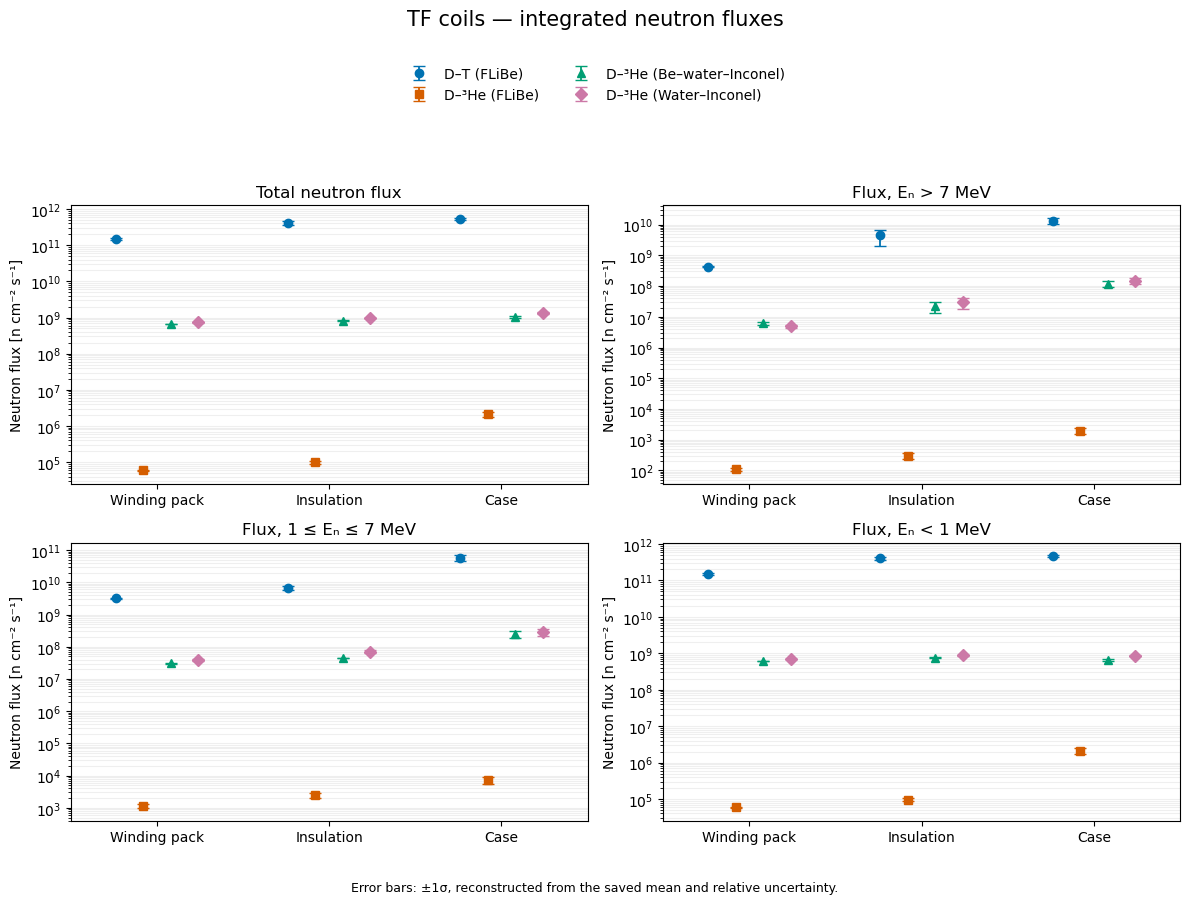

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (metric, title, _, _, _) in zip(axes.flat, FLUX_ROWS):
    component_plot(ax, metric, title, "Neutron flux [n cm⁻² s⁻¹]")
finish_figure(fig, axes, "TF coils — integrated neutron fluxes", "flux_comparison")

### Deposited power

Total deposited power in each TF component, in MW, at the source strengths
used by the original postprocessing notebooks.

Saved: models/comparison/tf_coil_plots/power_comparison.pdf
Saved: models/comparison/tf_coil_plots/power_comparison.png


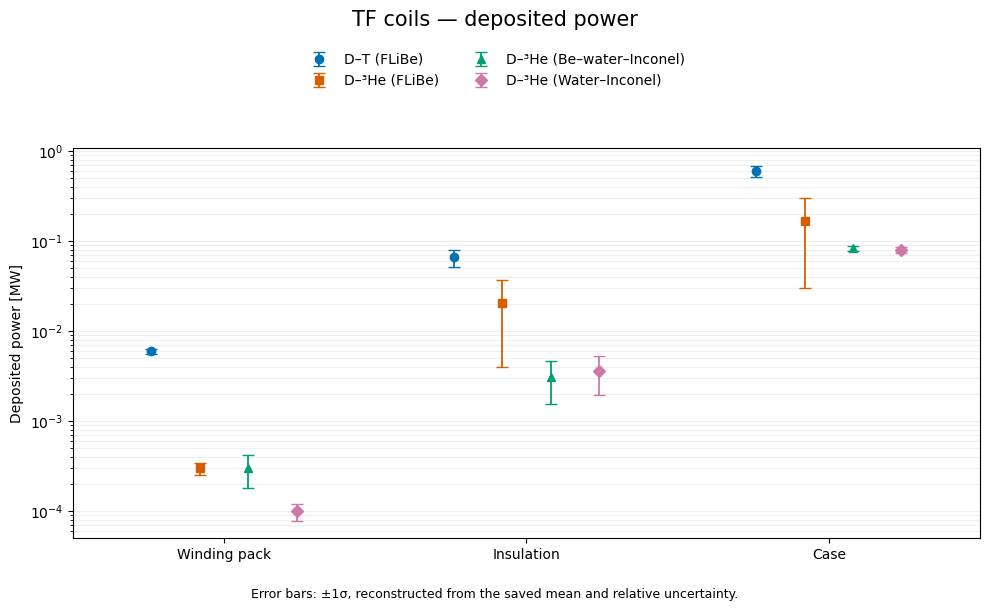

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
component_plot(ax, "power", "", "Deposited power [MW]")
finish_figure(fig, ax, "TF coils — deposited power", "power_comparison")

### Annual DPA on YBCO and total TBR

DPA is expressed per full power year (FPY), as in the `DPA =` output of the
source notebooks. Total TBR is copied from their `TBR_total` results.

Saved: models/comparison/tf_coil_plots/global_comparison.pdf
Saved: models/comparison/tf_coil_plots/global_comparison.png


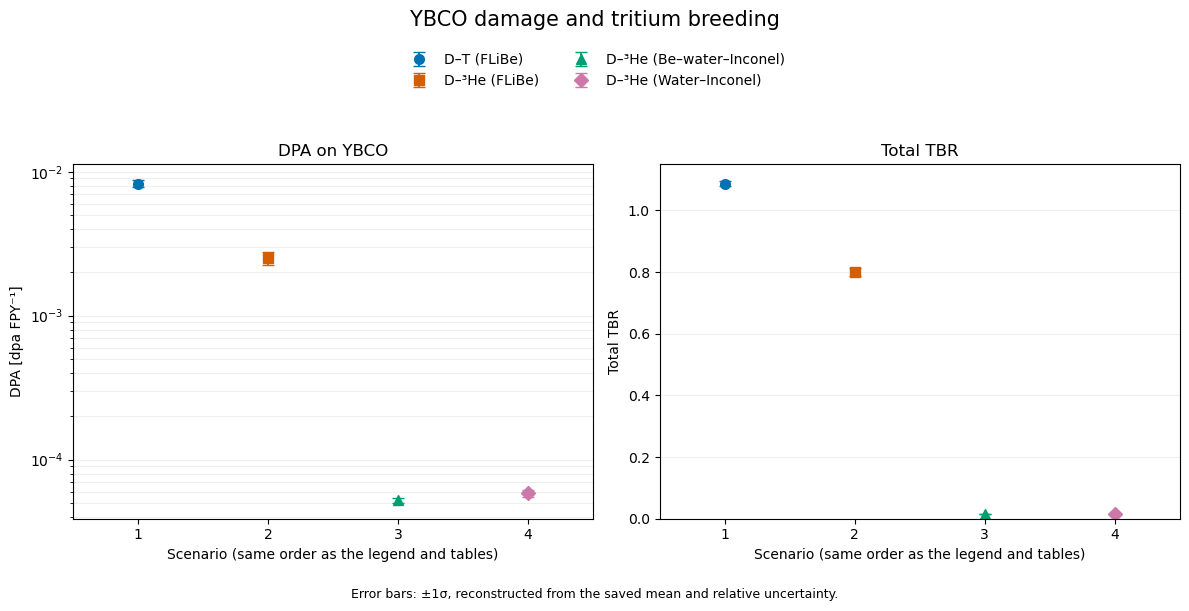

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (metric, title, _, unit, _) in zip(axes, GLOBAL_ROWS):
    means, errors = plot_values(None, metric)
    for index, (name, _, _) in enumerate(CONFIGURATIONS):
        ax.errorbar(
            index, means[index], yerr=errors[index], fmt=MARKERS[index],
            linestyle="none", color=COLORS[index], markersize=7,
            capsize=4, elinewidth=1.3, label=name,
        )
    # The shared legend identifies each scenario; numbers keep ticks compact.
    ax.set_xticks(range(len(CONFIGURATIONS)))
    ax.set_xticklabels([str(index + 1) for index in range(len(CONFIGURATIONS))])
    ax.set_xlabel("Scenario (same order as the legend and tables)")
    ax.set_xlim(-0.5, len(CONFIGURATIONS) - 0.5)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel("DPA [dpa FPY⁻¹]" if metric == "dpa" else "Total TBR")
    if metric == "dpa":
        ax.set_yscale("log")
    else:
        ax.set_ylim(bottom=0)
    ax.grid(axis="y", which="both", alpha=0.2)
    ax.set_axisbelow(True) 
finish_figure(fig, axes, "YBCO damage and tritium breeding", "global_comparison")